In [1]:
!pip install ../../../PyAlphaShape//

Defaulting to user installation because normal site-packages is not writeable
Processing /Users/niklasmelton/code/PyAlphaShape
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for pyalphashape: filename=pyalphashape-0.1.0-py3-none-any.whl size=23047 sha256=329e405c7f29a2b89f51165df2859c430f6cdd7c77c16f9362c05a95f6035091
  Stored in directory: /private/var/folders/60/rg8jprws4px3p6vsl80q8zg00000gn/T/pip-ephem-wheel-cache-ckre5s9_/wheels/41/bc/61/9d626df6793fa2c0126903051fc450a88cba0d696fe066517d
Successfully built pyalphashape
  Attempting uninstall: pyalphashape
    Found existing installation: pyalphashape 0.1.0
    Uninstalling pyalphashape-0.1.0:
      Successfully uninstalled pyalphashape-0.1.0

[notice] A new release of pip is available: 24.2 -> 25.0.1
[notice] To update, run: /Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip


In [3]:
from pyalphashape import AlphaShape, plot_polygon_edges
import numpy as np
import matplotlib.pyplot as plt

In [4]:
np.random.seed(42)
data = np.random.random((100, 2))

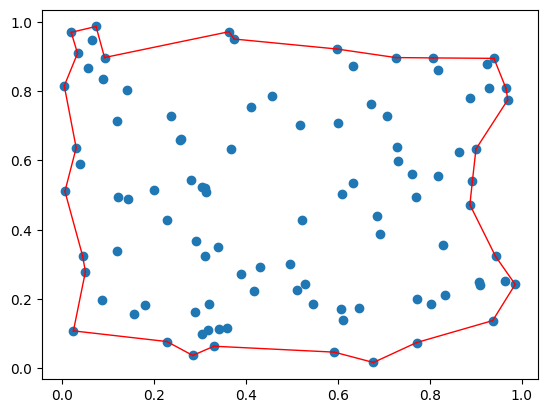

In [5]:
s = AlphaShape(data, alpha=7.0)
fig, ax = plt.subplots()
ax.scatter(data[:,0], data[:,1])
edges = [(e1, e2) for e1, e2 in s.perimeter_edges]

plot_polygon_edges(
    edges, ax, line_width=1, line_color="r"
)
plt.show()

In [6]:
s.distance_to_surface(np.array([0.5,0.5]))

0.0

Data has shape: (150, 2)
Prepared data has shape: (150, 2)
3 clusters found


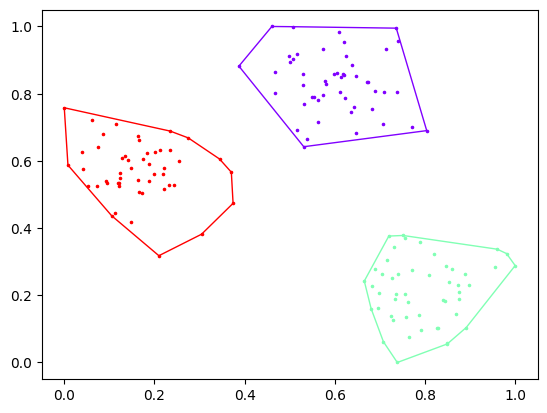

In [1]:
from sklearn.datasets import make_blobs
import matplotlib.pyplot as plt
from AlphaART import AlphaART

data, target = make_blobs(
    n_samples=150,
    centers=3,
    cluster_std=0.50,
    random_state=0,
    shuffle=False,
)
print("Data has shape:", data.shape)

params = {"rho": 0.48, "alpha": 0.0}
cls = AlphaART(**params)

X = cls.prepare_data(data)
print("Prepared data has shape:", X.shape)

y = cls.fit_predict(X)

print(f"{cls.n_clusters} clusters found")

cls.visualize(X, y)
plt.show()


Prepared data has shape: (150, 2)


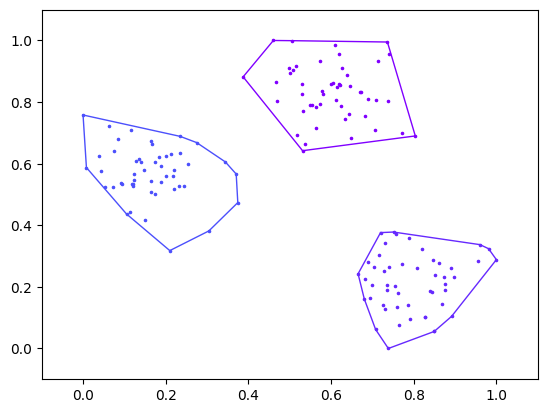

In [7]:
cls = AlphaART(**params)

X = cls.prepare_data(data)
print("Prepared data has shape:", X.shape)

y = cls.fit_gif(X, filename="hull_art_fit.gif")

Data has shape: (150, 2)
Prepared data has shape: (150, 2)
3 clusters found


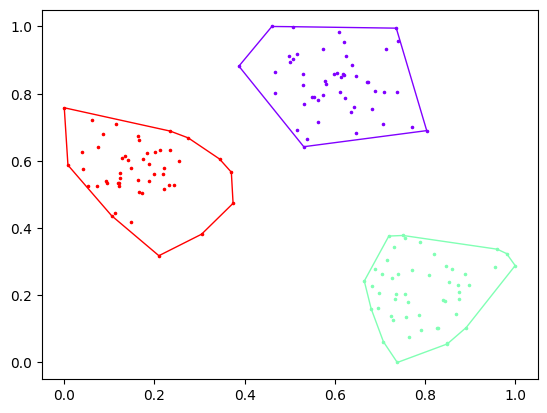

In [8]:
import numpy as np
from sklearn.datasets import load_iris, make_blobs
import matplotlib.pyplot as plt

from artlib import SimpleARTMAP


# def cluster_iris():
#     from sklearn.model_selection import train_test_split
#     from sklearn.metrics import classification_report
#     import umap.plot

#     data, target = load_iris(return_X_y=True)
#     print("Data has shape:", data.shape)

#     X_train, X_test, y_train, y_test = train_test_split(
#         X, target, test_size=0.33, random_state=0
#     )

#     params = {"rho": 0.0, "alpha": 0.0, "beta": 1.0}
#     art = FuzzyART(**params)
#     # params = {
#     #     "rho": 0.0,
#     #     "s_init": 0.9,
#     #     "lr_b": 0.1,
#     #     "lr_w": 0.1,
#     #     "lr_s": 0.1
#     # }
#     # art = QuadraticNeuronART(**params)

#     X = art.prepare_data(data)
#     print("Prepared data has shape:", X.shape)

#     cls = SimpleARTMAP(art)

#     cls = cls.fit(X_train, y_train)

#     print(f"{len(np.unique(cls.labels_a))} clusters found")

#     _, y_pred = cls.predict(X_test)

#     print(classification_report(y_test, y_pred))

#     mapper = umap.UMAP().fit(X_test)

#     umap.plot.points(
#         mapper, labels=y_pred, color_key_cmap="Paired", background="black"
#     )
#     umap.plot.plt.show()


data, target = make_blobs(
    n_samples=150,
    centers=3,
    cluster_std=0.50,
    random_state=0,
    shuffle=False,
)
print("Data has shape:", data.shape)

params = {"rho": 0.0, "alpha": 0.0}
art = AlphaART(**params)

X = art.prepare_data(data)
print("Prepared data has shape:", X.shape)

cls = SimpleARTMAP(art)

cls = cls.fit(X, target)
y = cls.labels_

print(f"{cls.module_a.n_clusters} clusters found")

cls.visualize(X, y)

plt.show()



In [1]:
!pip install ../../.

Defaulting to user installation because normal site-packages is not writeable
Processing /Users/niklasmelton/code/AdaptiveResonanceLib
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for artlib: filename=artlib-0.1.3-cp39-cp39-macosx_10_9_universal2.whl size=301275 sha256=e70f04e0ccebbebaab4016ad404d2f5fdd36088200624f3e4ceb867518b3a863
  Stored in directory: /private/var/folders/60/rg8jprws4px3p6vsl80q8zg00000gn/T/pip-ephem-wheel-cache-s3vxsp__/wheels/00/26/74/a797b75203ab88097ff326e33101e51d1788942a404ec4aa0d
Successfully built artlib
  Attempting uninstall: artlib
    Found existing installation: artlib 0.1.3
    Uninstalling artlib-0.1.3:
      Successfully uninstalled artlib-0.1.3

[notice] A new release of pip is available: 24.2 -> 25.0.1
[notice] To update, run: /Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip


In [1]:
import numpy as np
from scipy.spatial import ConvexHull, KDTree

def presort_for_alpha(points: np.ndarray,
                      alpha: float,
                      seed_layer: int = 1) -> np.ndarray:
    """
    Return a reordered copy of `points` that is well‑suited for incremental
    α‑shape construction.

    Parameters
    ----------
    points      : (N,d) array
    alpha       : α used for the shape (needed for the distance window)
    seed_layer  : how many hull layers to peel off before incremental insert

    Returns
    -------
    points_sorted : (N,d) array
    """
    pts = points.copy()
    d   = pts.shape[1]
    r_filter = np.inf if alpha <= 0 else 1.0 / alpha

    seed_idx = []
    remaining = np.arange(len(pts))

    # -------- Stage 1 : convex‑hull peeling --------------------------
    for _ in range(seed_layer):
        if len(remaining) < d + 1:
            break
        hull = ConvexHull(pts[remaining])
        layer = remaining[hull.vertices]
        seed_idx.extend(layer.tolist())
        remaining = np.setdiff1d(remaining, layer, assume_unique=True)

    if len(seed_idx) < d + 1:
        # fall back to random if hull failed (degenerate cloud)
        extra = remaining[: (d + 1 - len(seed_idx))]
        seed_idx.extend(extra.tolist())
        remaining = np.setdiff1d(remaining, extra, assume_unique=True)

    # -------- Stage 2 : sort by distance to hull ---------------------
    if len(remaining):
        hull_pts = pts[seed_idx]
        tree = KDTree(hull_pts)
        dists, _ = tree.query(pts[remaining])
        order = np.argsort(dists)          # closest‑to‑hull first
        remaining = remaining[order]

    # -------- concatenate & return -----------------------------------
    return np.concatenate([seed_idx, remaining])


Data has shape: (500, 2)
Prepared data has shape: (500, 2)
3 clusters found


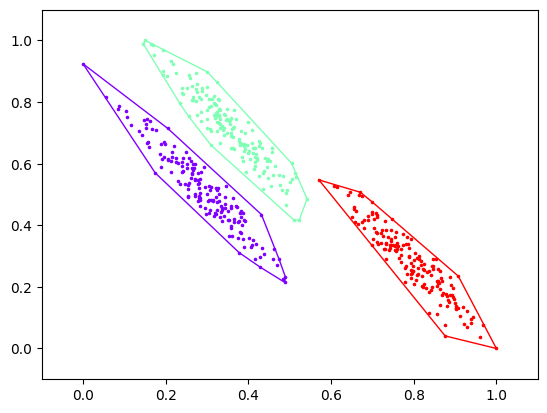

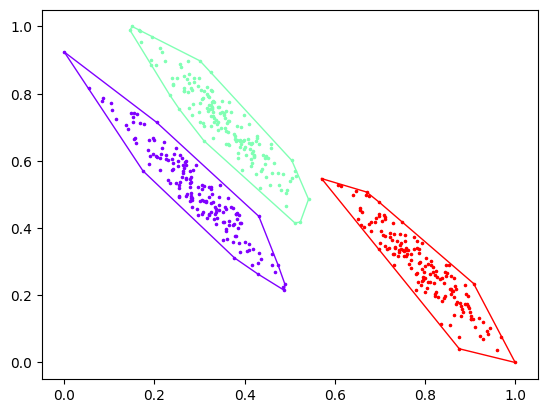

In [4]:
import numpy as np
from sklearn.datasets import load_iris, make_blobs
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
import matplotlib.pyplot as plt
from AlphaART import AlphaART

from artlib import SimpleARTMAP

random_state = 170
data, target = make_blobs(n_samples=500, random_state=random_state)
transformation = [[0.6, -0.6], [-0.4, 0.8]]
X_aniso = np.dot(data, transformation)

print("Data has shape:", data.shape)

params = {"rho": 0.0, "alpha": 0.0}
art = AlphaART(**params)

X = art.prepare_data(X_aniso)
print("Prepared data has shape:", X.shape)

sorted_idx = presort_for_alpha(X, 0.0)
X = X[sorted_idx]
target = target[sorted_idx]

cls = SimpleARTMAP(art)

cls = cls.fit_gif(X, target, filename="aniso_alpha_art.gif", fps=25, final_hold_secs=2)
y = cls.labels_

print(f"{cls.module_a.n_clusters} clusters found")

cls.visualize(X, y)

plt.show()

Data has shape: (1000, 2)
Prepared data has shape: (1000, 2)
14 clusters found


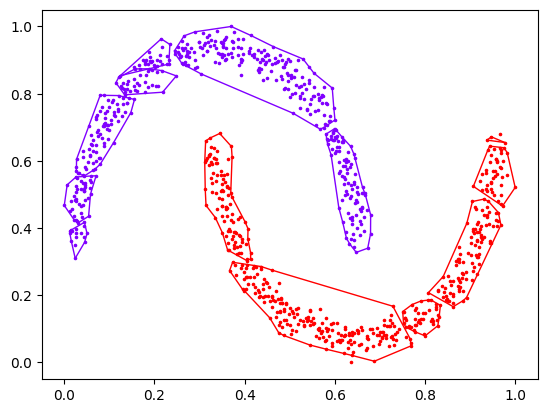

In [33]:
import numpy as np
from sklearn.datasets import load_iris, make_blobs
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
import matplotlib.pyplot as plt
from AlphaART import AlphaART

from artlib import SimpleARTMAP

random_state = 170
data, target = make_moons(n_samples=500, noise=0.05, random_state=random_state)

print("Data has shape:", data.shape)
alpha = 5.0
params = {"rho": 0.0, "alpha": alpha}
art = AlphaART(**params)

X = art.prepare_data(data)
print("Prepared data has shape:", X.shape)

sorted_idx = presort_for_alpha(X, alpha)
X = X[sorted_idx]
target = target[sorted_idx]

cls = SimpleARTMAP(art)

# cls = cls.fit_gif(X, target, filename="moons_alpha_art.gif", fps=25, final_hold_secs=2)
cls.fit(X, target)
y = cls.labels_

print(f"{cls.module_a.n_clusters} clusters found")

cls.visualize(X, y)

plt.show()

In [16]:
!pip install ../../.

Defaulting to user installation because normal site-packages is not writeable
Processing /Users/niklasmelton/code/AdaptiveResonanceLib
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for artlib: filename=artlib-0.1.3-cp39-cp39-macosx_10_9_universal2.whl size=305493 sha256=e8b15f8da71ad9b1947e38a42e0bc1eb4943893f0534fa64a59cbd5f488e3fb2
  Stored in directory: /private/var/folders/60/rg8jprws4px3p6vsl80q8zg00000gn/T/pip-ephem-wheel-cache-hoj0g901/wheels/00/26/74/a797b75203ab88097ff326e33101e51d1788942a404ec4aa0d
Successfully built artlib
  Attempting uninstall: artlib
    Found existing installation: artlib 0.1.3
    Uninstalling artlib-0.1.3:
      Successfully uninstalled artlib-0.1.3

[notice] A new release of pip is available: 24.2 -> 25.0.1
[notice] To update, run: /Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip


In [14]:
!pip install ../../../PyAlphaShape/.

Defaulting to user installation because normal site-packages is not writeable
Processing /Users/niklasmelton/code/PyAlphaShape
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for pyalphashape: filename=pyalphashape-0.1.0-py3-none-any.whl size=23066 sha256=0bf6cdb8c8e67e3132d10141fa24eef70c314e83c85f1e1792dec135be18b52d
  Stored in directory: /private/var/folders/60/rg8jprws4px3p6vsl80q8zg00000gn/T/pip-ephem-wheel-cache-va1r5gc3/wheels/41/bc/61/9d626df6793fa2c0126903051fc450a88cba0d696fe066517d
Successfully built pyalphashape
  Attempting uninstall: pyalphashape
    Found existing installation: pyalphashape 0.1.0
    Uninstalling pyalphashape-0.1.0:
      Successfully uninstalled pyalphashape-0.1.0

[notice] A new release of pip is available: 24.2 -> 25.0.1
[notice] To update, run: /Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip
